# Exercise 4 · Spam filter

**Book:** Chapter 3, Exercise 4

**Task:** classify SpamAssassin emails with high precision and recall, using a configurable email → word-count → sparse-vector pipeline.

In [1]:
import re
import string
from collections import Counter
from email import policy
from email.parser import BytesParser

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from homl.datasets import load_spam
from homl.plotting import RANDOM_STATE, save_fig

## a–b. Load and get to know the data
2,500 ham and 500 spam raw emails.

In [2]:
ham_raw, spam_raw = load_spam()
parser = BytesParser(policy=policy.default)
ham_emails = [parser.parsebytes(raw) for raw in ham_raw]
spam_emails = [parser.parsebytes(raw) for raw in spam_raw]
print(len(ham_emails), "ham /", len(spam_emails), "spam")
print(ham_emails[1].get("Subject"))
print(spam_emails[6].get("Subject"))

2500 ham / 500 spam
[zzzzteana] RE: Alexander
FORTUNE 500 COMPANY HIRING, AT HOME REPS.


Ham is mostly plain text; spam is much more often HTML:

In [3]:
def structure(email) -> str:
    if email.is_multipart():
        return "multipart(" + ", ".join(structure(p) for p in email.get_payload()) + ")"
    return email.get_content_type()

structures = pd.DataFrame({
    "ham": pd.Series([structure(e) for e in ham_emails]).value_counts().head(6),
    "spam": pd.Series([structure(e) for e in spam_emails]).value_counts().head(6),
}).fillna(0).astype(int)
structures

,ham,spam
multipart(multipart(text/html)),0,5
multipart(text/html),0,20
multipart(text/plain),3,19
"multipart(text/plain, application/octet-stream)",2,0
"multipart(text/plain, application/pgp-signature)",66,0
"multipart(text/plain, text/html)",8,45
"multipart(text/plain, text/plain)",4,0
text/html,0,183
text/plain,2408,218


## c. Train/test split
Stratified 80/20.

In [4]:
X = np.array(ham_emails + spam_emails, dtype=object)
y = np.array([0] * len(ham_emails) + [1] * len(spam_emails))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(len(X_train), len(X_test))

2400 600


## d. Preparation pipeline
### Email → plain text
Prefer `text/plain`, else convert HTML to text (links become a `HYPERLINK` token).

In [5]:
import html as html_lib


def html_to_plain_text(html: str) -> str:
    text = re.sub(r"<head.*?>.*?</head>", "", html, flags=re.M | re.S | re.I)
    text = re.sub(r"<a\s.*?>", " HYPERLINK ", text, flags=re.M | re.S | re.I)
    text = re.sub(r"<.*?>", "", text, flags=re.M | re.S)
    text = re.sub(r"(\s*\n)+", "\n", text, flags=re.M | re.S)
    return html_lib.unescape(text)


def part_content(part) -> str:
    try:
        return part.get_content()
    except Exception:  # unknown or broken charset
        payload = part.get_payload(decode=True) or b""
        return payload.decode("latin-1", errors="ignore")


def email_to_text(email) -> str:
    html = None
    for part in email.walk():
        ctype = part.get_content_type()
        if ctype not in ("text/plain", "text/html"):
            continue
        content = part_content(part)
        if not isinstance(content, str):
            continue
        if ctype == "text/plain":
            return content
        html = content
    return html_to_plain_text(html) if html else ""


html_spam = next(e for e in X_train[y_train == 1] if e.get_content_type() == "text/html")
print(email_to_text(html_spam)[:400])


 
       HYPERLINK
		Unlist Information
		This message is brought to you by Answer-us.com in
		compliance with current federal laws. To find out more about Answer-us.com visit
         HYPERLINK
         HYPERLINK
        http://www.answer-us.com.
        You are receiving this mailing because you or someone you know has
        registered this email address to receive special offers from an Answ


### Text → word counts
Every preprocessing option is a hyperparameter, so a grid search can decide which ones help.

In [6]:
URL_RE = re.compile(r"(?:https?://|www\.)[^\s<>\"']+", re.I)
NUMBER_RE = re.compile(r"\d+(?:\.\d*)?(?:[eE][+-]?\d+)?")
PUNCT_TABLE = str.maketrans({c: " " for c in string.punctuation})
stemmer = PorterStemmer()


class EmailToWordCounter(BaseEstimator, TransformerMixin):
    """Turn parsed emails into Counter objects of (optionally normalized) words."""

    def __init__(self, strip_headers=True, lower_case=True, remove_punctuation=True,
                 replace_urls=True, replace_numbers=True, stemming=True):
        self.strip_headers = strip_headers
        self.lower_case = lower_case
        self.remove_punctuation = remove_punctuation
        self.replace_urls = replace_urls
        self.replace_numbers = replace_numbers
        self.stemming = stemming

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        counters = []
        for email in X:
            text = email_to_text(email)
            if not self.strip_headers:
                text = f"{email.get('Subject', '')} {email.get('From', '')}\n{text}"
            if self.lower_case:
                text = text.lower()
            if self.replace_urls:
                text = URL_RE.sub(" URL ", text)
            if self.replace_numbers:
                text = NUMBER_RE.sub(" NUMBER ", text)
            if self.remove_punctuation:
                text = text.translate(PUNCT_TABLE)
            words = Counter(text.split())
            if self.stemming:
                stemmed = Counter()
                for word, count in words.items():
                    stemmed[stemmer.stem(word)] += count
                words = stemmed
            counters.append(words)
        return np.array(counters, dtype=object)


class WordCounterToVector(BaseEstimator, TransformerMixin):
    """Map word counters to a sparse matrix over the `vocabulary_size` most frequent training words.

    Column 0 counts all out-of-vocabulary words.
    """

    def __init__(self, vocabulary_size=1000):
        self.vocabulary_size = vocabulary_size

    def fit(self, X, y=None):
        total = Counter()
        for counter in X:
            for word, count in counter.items():
                total[word] += min(count, 10)  # cap so one long email can't dominate
        most_common = total.most_common(self.vocabulary_size)
        self.vocabulary_ = {word: i + 1 for i, (word, _) in enumerate(most_common)}
        return self

    def transform(self, X):
        rows, cols, data = [], [], []
        for row, counter in enumerate(X):
            for word, count in counter.items():
                rows.append(row)
                cols.append(self.vocabulary_.get(word, 0))
                data.append(count)
        return csr_matrix((data, (rows, cols)), shape=(len(X), self.vocabulary_size + 1))


sample_counts = EmailToWordCounter().fit_transform(X_train[:3])
print(sample_counts[0].most_common(10))
vec = WordCounterToVector(vocabulary_size=10).fit(sample_counts)
print(vec.vocabulary_)
print(vec.transform(sample_counts).toarray())

[('in', 6), ('of', 5), ('and', 5), ('the', 5), ('you', 5), ('r', 4), ('that', 3), ('i', 3), ('a', 3), ('eateri', 3)]
{'number': 1, 'and': 2, 'in': 3, 'url': 4, 'you': 5, 'of': 6, 'the': 7, 'to': 8, 's': 9, 'thi': 10}
[[157   1   5   6   1   5   5   5   1   1   0]
 [108  20   6   4   9   3   0   2   4   0   5]
 [ 66   2   1   1   1   1   3   1   2   5   1]]


## e. Classifiers
Word counting runs once with default options; classifiers are compared with 3-fold CV.

In [7]:
counter = EmailToWordCounter()
train_counts = counter.fit_transform(X_train)
vectorizer = WordCounterToVector(vocabulary_size=1000)
X_train_vec = vectorizer.fit_transform(train_counts)

candidates = {
    "Logistic regression": LogisticRegression(max_iter=1_000, random_state=RANDOM_STATE),
    "Linear SVC": LinearSVC(C=0.1, max_iter=5_000, random_state=RANDOM_STATE),
    "Multinomial naive Bayes": MultinomialNB(),
}
rows = []
for name, clf in candidates.items():
    acc = cross_val_score(clf, X_train_vec, y_train, cv=3, scoring="accuracy").mean()
    f1 = cross_val_score(clf, X_train_vec, y_train, cv=3, scoring="f1").mean()
    rows.append((name, acc, f1))
pd.DataFrame(rows, columns=["model", "CV accuracy", "CV F1 (spam)"]).round(4)

/home/claude/homl-workspace/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/home/claude/homl-workspace/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,model,CV accuracy,CV F1 (spam)
0,Logistic regression,0.9842,0.9513
1,Linear SVC,0.9792,0.9346
2,Multinomial naive Bayes,0.9508,0.8656


## Do the preprocessing options matter?
Grid search over the full pipeline, toggling one option family at a time.

In [8]:
pipeline = Pipeline([
    ("counter", EmailToWordCounter()),
    ("vectorizer", WordCounterToVector()),
    ("clf", LogisticRegression(max_iter=1_000, random_state=RANDOM_STATE)),
])
param_grid = [
    {"counter__stemming": [True, False], "vectorizer__vocabulary_size": [500, 1000, 3000]},
    {"counter__replace_urls": [False], "counter__replace_numbers": [False]},
    {"counter__strip_headers": [False]},
]
search = GridSearchCV(pipeline, param_grid, cv=3, scoring="f1", n_jobs=-1)
search.fit(X_train, y_train)
res = pd.DataFrame(search.cv_results_)
res["options"] = res["params"].astype(str)
res[["options", "mean_test_score"]].sort_values("mean_test_score", ascending=False).round(4)

,options,mean_test_score
7,{'counter__strip_headers': False},0.9620
3,"{'counter__stemming': False, 'vectorizer__voca...",0.9594
1,"{'counter__stemming': True, 'vectorizer__vocab...",0.9594
2,"{'counter__stemming': True, 'vectorizer__vocab...",0.9591
6,"{'counter__replace_numbers': False, 'counter__...",0.9578
5,"{'counter__stemming': False, 'vectorizer__voca...",0.9563
4,"{'counter__stemming': False, 'vectorizer__voca...",0.9552
0,"{'counter__stemming': True, 'vectorizer__vocab...",0.9479


## Final evaluation on the test set

chosen options: {'counter__strip_headers': False}


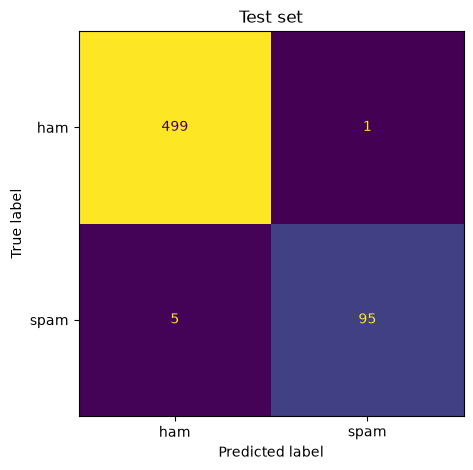

In [9]:
best_pipeline = search.best_estimator_
print("chosen options:", search.best_params_)
y_pred = best_pipeline.predict(X_test)
precision, recall, f1 = precision_score(y_test, y_pred), recall_score(y_test, y_pred), f1_score(y_test, y_pred)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["ham", "spam"], colorbar=False)
plt.title("Test set")
save_fig("test_confusion_matrix")
plt.show()

Largest logistic-regression weights:

In [10]:
vocab = best_pipeline.named_steps["vectorizer"].vocabulary_
index_to_word = {i: w for w, i in vocab.items()} | {0: "<other>"}
coefs = best_pipeline.named_steps["clf"].coef_[0]
order = np.argsort(coefs)
pd.DataFrame({
    "most 'ham' words": [index_to_word[i] for i in order[:12]],
    "most 'spam' words": [index_to_word[i] for i in order[::-1][:12]],
})

,most 'ham' words,most 'spam' words
0,re,hyperlink
1,spamassassin,click
2,rssfeed,pleas
3,taint,visit
4,date,free
5,wrote,you
6,use,remov
7,group,our
8,t,guarante
9,url,access


## Results

In [11]:
pd.DataFrame({"precision": [precision], "recall": [recall], "F1": [f1]}, index=["test set (600 emails)"]).round(4)

,precision,recall,F1
test set (600 emails),0.9896,0.95,0.9694


**Takeaways**
- Bag-of-words with logistic regression gives 99.0% precision and 95.0% recall on the test set; preprocessing toggles barely move the score.
- Ham words like *spamassassin* and *taint* come from the source mailing lists, so part of the score is corpus-specific.
- "Easy ham" is easy; the corpus's "hard ham" would be a tougher test.